In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
RANDOM_STATE = 42
DATASET_DIR = "..\dataset"

CLASSES = ["stop", "ready", "go"]
LABEL_TO_ID = {"stop": 0, "ready": 1, "go": 2}
ID_TO_LABEL = {0: "stop", 1: "ready", 2: "go"}

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

In [4]:
def load_dataset(dataset_dir):
    image_paths = []
    labels = []

    for label in CLASSES:
        folder = os.path.join(dataset_dir, label)

        if not os.path.isdir(folder):
            raise FileNotFoundError(
                f"Folder dataset tidak ditemukan: {folder}"
            )

        for filename in sorted(os.listdir(folder)):
            if not filename.lower().endswith(IMAGE_EXTENSIONS):
                continue

            path = os.path.join(folder, filename)

            # Pastikan gambar dapat dibaca
            image = cv2.imread(path)

            if image is None:
                print(f"Peringatan: gambar dilewati: {path}")
                continue

            image_paths.append(path)
            labels.append(label)

    if not image_paths:
        raise ValueError("Tidak ada gambar valid dalam dataset.")

    return image_paths, labels


In [ ]:
def display_data_distribution_and_samples(image_paths, labels):
    # Menghitung jumlah gambar setiap label
    distribution = pd.Series(labels).value_counts().reindex(
        CLASSES, fill_value=0
    )

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        distribution.index,
        distribution.values,
        color=["red", "gold", "green"],
        edgecolor="black"
    )

    # Menampilkan jumlah di atas setiap batang
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=11
        )

    plt.title("Dataset Distribution Before Train-Test Split")
    plt.xlabel("Traffic Light Label")
    plt.ylabel("Number of Images")
    plt.xticks(CLASSES)
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

    samples_per_label = 3

    fig, axes = plt.subplots(
        len(CLASSES),
        samples_per_label,
        figsize=(12, 9)
    )

    for row, label in enumerate(CLASSES):
        # Mencari indeks gambar berdasarkan label
        indices = [
            i for i, current_label in enumerate(labels)
            if current_label == label
        ]

        # Mengambil maksimal 3 sampel secara acak
        rng = np.random.default_rng(RANDOM_STATE)
        selected_indices = rng.choice(
            indices,
            size=min(samples_per_label, len(indices)),
            replace=False
        ) if indices else []

        for col in range(samples_per_label):
            ax = axes[row, col]

            if col < len(selected_indices):
                idx = selected_indices[col]
                image = cv2.imread(image_paths[idx])

                if image is not None:
                    image_rgb = cv2.cvtColor(
                        image, cv2.COLOR_BGR2RGB
                    )
                    ax.imshow(image_rgb)
                    ax.set_title(
                        f"{label.upper()} - Sample {col + 1}"
                    )
                else:
                    ax.set_title("Image unavailable")
            else:
                ax.set_visible(False)

            ax.axis("off")

    plt.suptitle(
        "Original Image Samples by Traffic Light Label",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

    print("Dataset Distribution Before Splitting")
    print(distribution.to_string())
    print(f"\nTotal images: {distribution.sum()}")


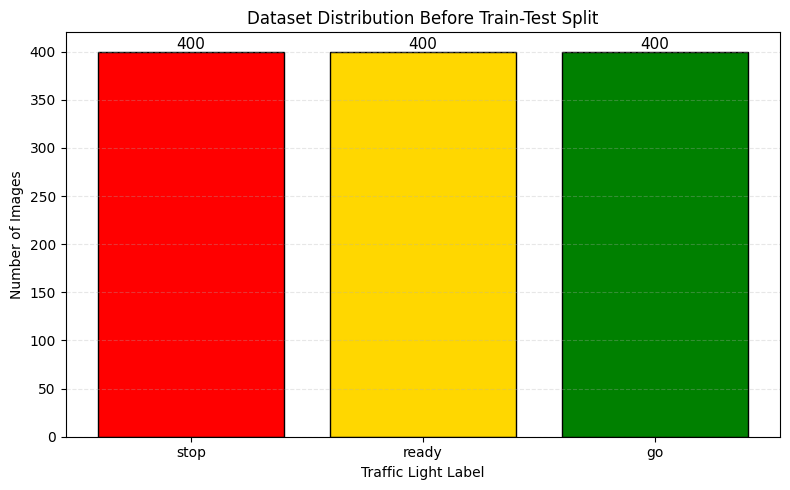

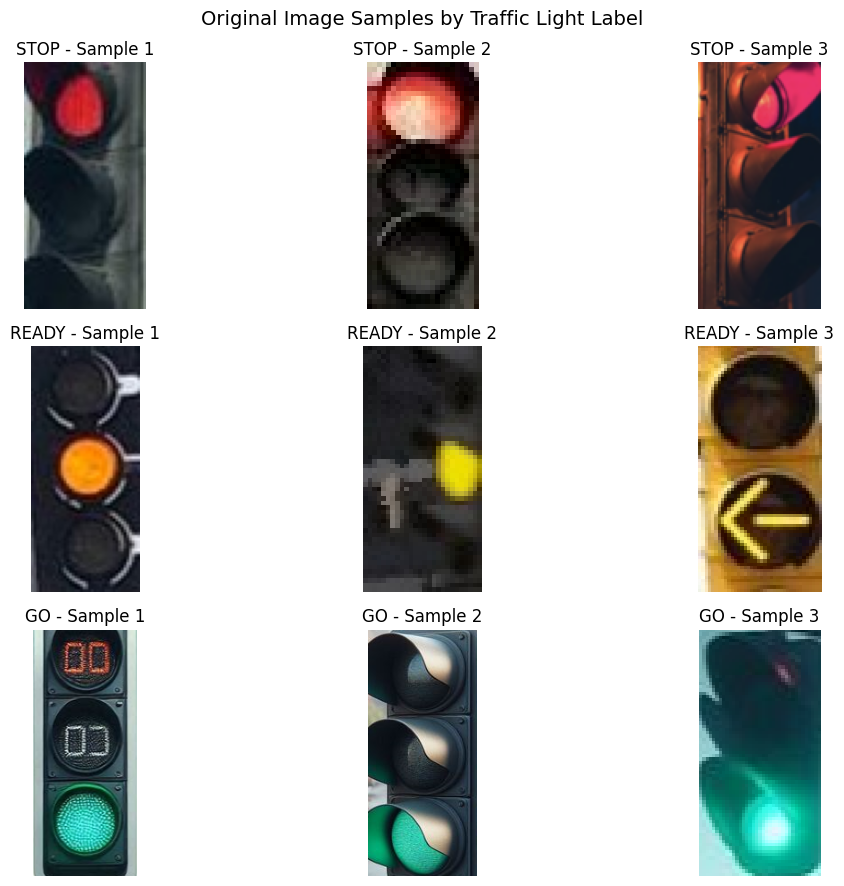

Dataset Distribution Before Splitting
stop     400
ready    400
go       400

Total images: 1200


In [25]:
image_paths, labels = load_dataset(DATASET_DIR)

# Menjalankan visualisasi sebelum split
display_data_distribution_and_samples(
    image_paths,
    labels
)

In [ ]:
X_train_paths, X_test_paths, y_train_labels, y_test_labels = (
    train_test_split(
        image_paths,
        labels,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=labels
    )
)

print("Total gambar valid:", len(image_paths))
print("Data training:", len(X_train_paths))
print("Data testing:", len(X_test_paths))

print("\nDistribusi training:")
print(pd.Series(y_train_labels).value_counts().reindex(CLASSES))

print("\nDistribusi testing:")
print(pd.Series(y_test_labels).value_counts().reindex(CLASSES))

Total gambar valid: 1200
Data training: 960
Data testing: 240

Distribusi training:
stop     320
ready    320
go       320
Name: count, dtype: int64

Distribusi testing:
stop     80
ready    80
go       80
Name: count, dtype: int64


In [6]:
def preprocess_image(image):
    # 1. Resize
    image = cv2.resize(image, (100, 200))

    # 2. Noise removal
    image = cv2.GaussianBlur(image, (5, 5), 0)

    # 3. Contrast enhancement menggunakan CLAHE
    image_lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(image_lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    l_channel = clahe.apply(l_channel)

    image_lab = cv2.merge([l_channel, a_channel, b_channel])
    image = cv2.cvtColor(image_lab, cv2.COLOR_LAB2BGR)

    # 4. Saturation enhancement
    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(image_hsv)

    s = np.clip(
        s.astype(np.float32) * 1.5, 0, 255
    ).astype(np.uint8)

    image_hsv = cv2.merge([h, s, v])
    image = cv2.cvtColor(image_hsv, cv2.COLOR_HSV2BGR)

    # 5. Intensity normalization pada kanal L
    image_lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(image_lab)

    l_channel = cv2.normalize(
        l_channel,
        None,
        alpha=0,
        beta=255,
        norm_type=cv2.NORM_MINMAX
    )

    image_lab = cv2.merge([l_channel, a_channel, b_channel])
    image = cv2.cvtColor(image_lab, cv2.COLOR_LAB2BGR)

    # 6. Color segmentation menggunakan HSV
    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Merah: hue berada pada dua rentang
    mask_red_1 = cv2.inRange(
        image_hsv,
        np.array([0, 100, 20]),
        np.array([10, 255, 255])
    )

    mask_red_2 = cv2.inRange(
        image_hsv,
        np.array([160, 100, 20]),
        np.array([179, 255, 255])
    )

    mask_red = cv2.bitwise_or(mask_red_1, mask_red_2)

    # Kuning
    mask_yellow = cv2.inRange(
        image_hsv,
        np.array([15, 80, 80]),
        np.array([35, 255, 255])
    )

    # Hijau
    mask_green = cv2.inRange(
        image_hsv,
        np.array([35, 60, 40]),
        np.array([90, 255, 255])
    )

    mask = cv2.bitwise_or(mask_red, mask_yellow)
    mask = cv2.bitwise_or(mask, mask_green)

    segmented_image = cv2.bitwise_and(
        image, image, mask=mask
    )

    return segmented_image

In [14]:
def preprocess_dataset(image_paths, labels):
    processed_images = []
    valid_labels = []
    valid_paths = []

    for path, label in zip(image_paths, labels):
        image = cv2.imread(path)

        if image is None:
            print(f"Gambar tidak dapat dibaca: {path}")
            continue

        # Preprocessing dilakukan di sini
        processed_image = preprocess_image(image)

        processed_images.append(processed_image)
        valid_labels.append(label)
        valid_paths.append(path)

    return processed_images, valid_labels, valid_paths

In [15]:
def display_processed_samples(images, labels, n=3):
    for label in CLASSES:
        indices = [
            i for i, item_label in enumerate(labels)
            if item_label == label
        ][:n]

        if not indices:
            continue

        fig, axes = plt.subplots(
            1, len(indices), figsize=(4 * len(indices), 5)
        )
        axes = np.atleast_1d(axes)

        for ax, idx in zip(axes, indices):
            image_rgb = cv2.cvtColor(
                images[idx], cv2.COLOR_BGR2RGB
            )
            ax.imshow(image_rgb)
            ax.set_title(label)
            ax.axis("off")

        plt.suptitle(f"Hasil Preprocessing: {label}")
        plt.tight_layout()
        plt.show()

In [16]:
# Preprocessing training dan testing secara terpisah
train_images_processed, y_train_labels, train_paths = (
    preprocess_dataset(X_train_paths, y_train_labels)
)

test_images_processed, y_test_labels, test_paths = (
    preprocess_dataset(X_test_paths, y_test_labels)
)

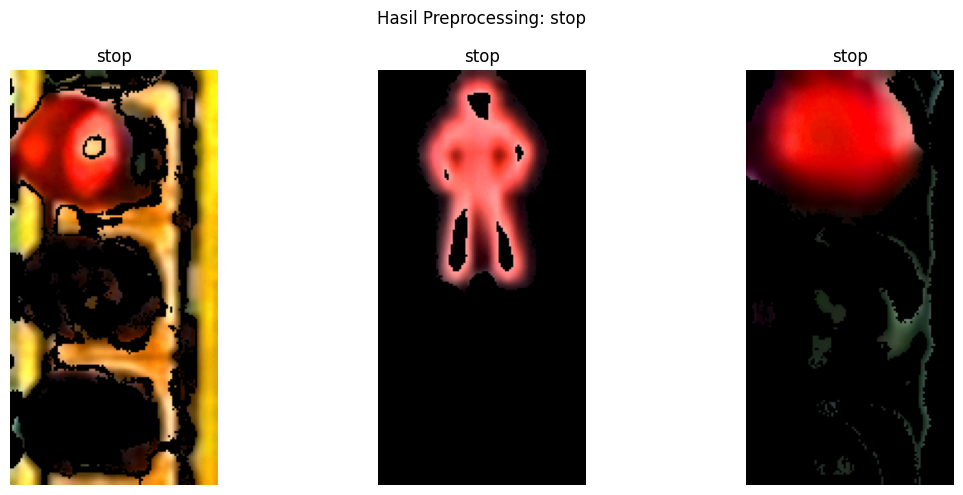

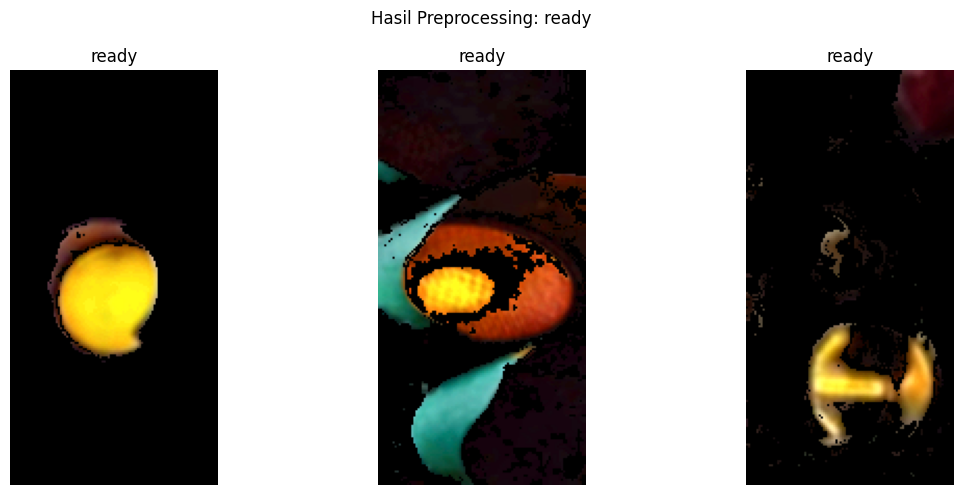

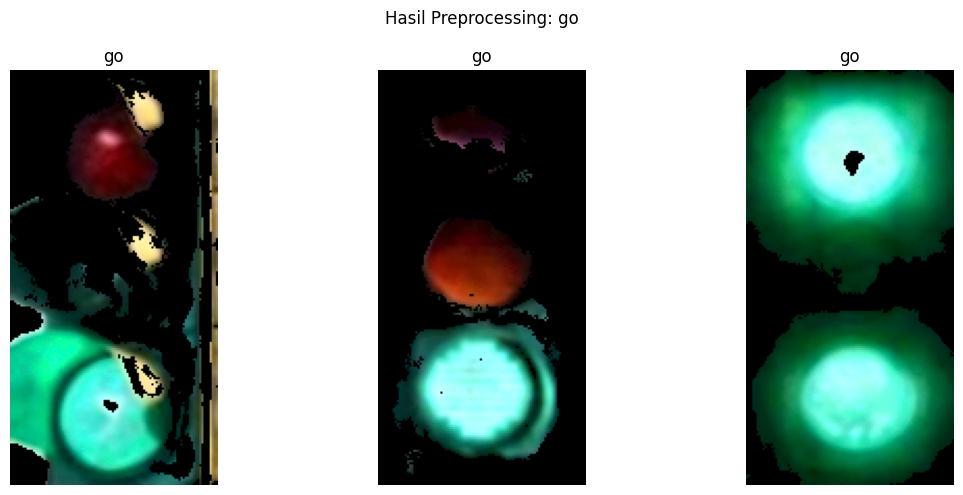

In [17]:
display_processed_samples(
    train_images_processed,
    y_train_labels
)

In [ ]:
def extract_features(image):
    # Rata-rata warna BGR: 3 fitur
    avg_color = np.mean(image, axis=(0, 1))

    # Histogram B, G, R: 256 fitur per kanal
    hist_b = cv2.calcHist(
        [image], [0], None, [256], [0, 256]
    ).flatten()

    hist_g = cv2.calcHist(
        [image], [1], None, [256], [0, 256]
    ).flatten()

    hist_r = cv2.calcHist(
        [image], [2], None, [256], [0, 256]
    ).flatten()

    # Normalisasi histogram agar jumlah piksel
    # tidak mendominasi fitur
    hist_b = hist_b / (image.shape[0] * image.shape[1])
    hist_g = hist_g / (image.shape[0] * image.shape[1])
    hist_r = hist_r / (image.shape[0] * image.shape[1])

    color_hist = np.concatenate([hist_b, hist_g, hist_r])

    return np.concatenate([avg_color, color_hist])

In [20]:
def extract_dataset_features(images, labels):
    features = [
        extract_features(image)
        for image in images
    ]

    encoded_labels = [
        LABEL_TO_ID[label]
        for label in labels
    ]

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(encoded_labels, dtype=np.int32)
    )

In [21]:
X_train, y_train = extract_dataset_features(
    train_images_processed,
    y_train_labels
)

X_test, y_test = extract_dataset_features(
    test_images_processed,
    y_test_labels
)

print("Fitur training:", X_train.shape)
print("Fitur testing:", X_test.shape)
print("Jumlah fitur per gambar:", X_train.shape[1])

Fitur training: (960, 771)
Fitur testing: (240, 771)
Jumlah fitur per gambar: 771


In [22]:
# Normalisasi fitur
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
# Definisi model
models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        kernel="linear",
        random_state=RANDOM_STATE
    )
}

# Training model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} selesai dilatih.")

KNN selesai dilatih.
Random Forest selesai dilatih.
SVM selesai dilatih.


In [10]:
def evaluate_models(models, X_test, y_test):
    results = []
    predictions_by_model = {}

    class_ids = [LABEL_TO_ID[label] for label in CLASSES]

    for name, model in models.items():
        predictions = model.predict(X_test)
        predictions_by_model[name] = predictions

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test,
                predictions,
                labels=class_ids,
                average="weighted",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                predictions,
                labels=class_ids,
                average="weighted",
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_test,
                predictions,
                labels=class_ids,
                average="weighted",
                zero_division=0
            )
        })

        print(f"\nClassification Report — {name}")
        print(
            classification_report(
                y_test,
                predictions,
                labels=class_ids,
                target_names=CLASSES,
                zero_division=0
            )
        )

    return pd.DataFrame(results), predictions_by_model


df_metrics, predictions_by_model = evaluate_models(
    models,
    X_test_scaled,
    y_test
)

print("\nHasil Evaluasi:")
print(df_metrics.round(4).to_string(index=False))

c:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^


Classification Report — KNN
              precision    recall  f1-score   support

        stop       0.89      0.94      0.91        80
       ready       0.92      0.90      0.91        80
          go       0.99      0.96      0.97        80

    accuracy                           0.93       240
   macro avg       0.93      0.93      0.93       240
weighted avg       0.93      0.93      0.93       240


Classification Report — Random Forest
              precision    recall  f1-score   support

        stop       1.00      0.99      0.99        80
       ready       0.99      1.00      0.99        80
          go       1.00      1.00      1.00        80

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240


Classification Report — SVM
              precision    recall  f1-score   support

        stop       0.99      0.96      0.97        80
       ready       0.96      1.0

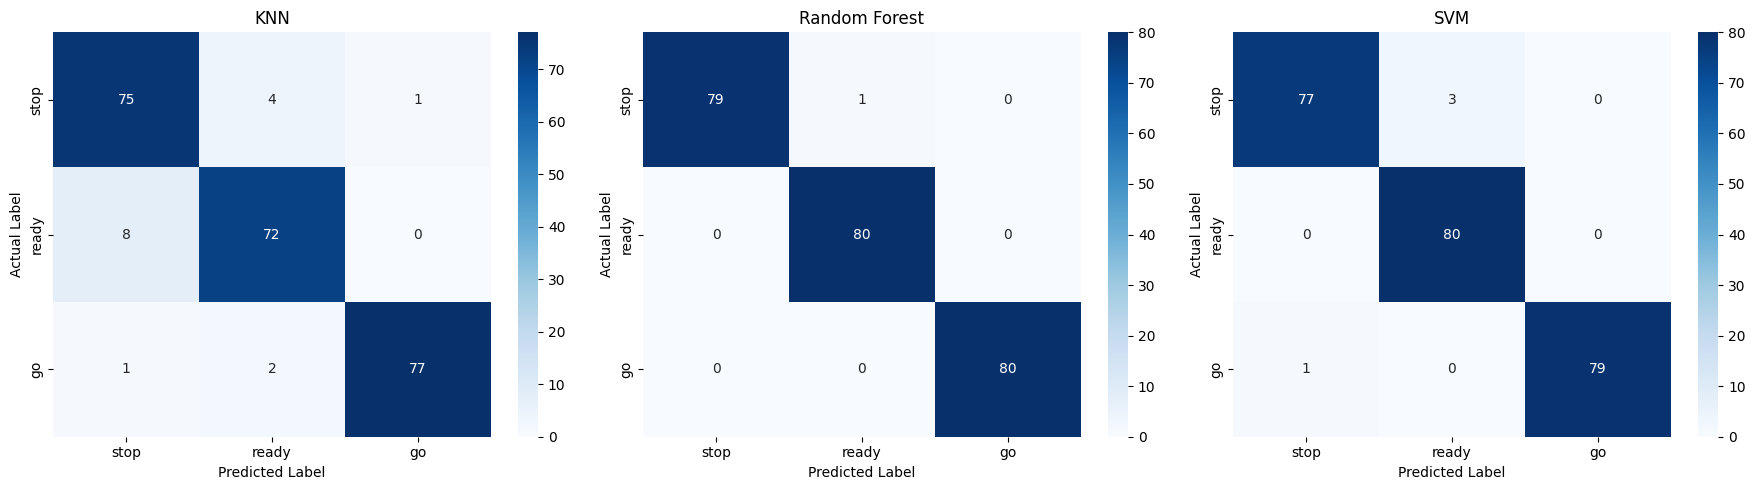

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, predictions_by_model.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[LABEL_TO_ID[label] for label in CLASSES]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [12]:
df_predictions = pd.DataFrame({
    "Image": test_paths,
    "Actual Label": [ID_TO_LABEL[int(y)] for y in y_test],
    "KNN Prediction": [
        ID_TO_LABEL[int(y)]
        for y in predictions_by_model["KNN"]
    ],
    "Random Forest Prediction": [
        ID_TO_LABEL[int(y)]
        for y in predictions_by_model["Random Forest"]
    ],
    "SVM Prediction": [
        ID_TO_LABEL[int(y)]
        for y in predictions_by_model["SVM"]
    ]
})

display(df_predictions)

# Menampilkan gambar yang salah diklasifikasikan
df_errors = df_predictions[
    (df_predictions["Actual Label"] != df_predictions["KNN Prediction"]) |
    (df_predictions["Actual Label"] != df_predictions["Random Forest Prediction"]) |
    (df_predictions["Actual Label"] != df_predictions["SVM Prediction"])
]

print("Jumlah gambar dengan setidaknya satu prediksi salah:", len(df_errors))
display(df_errors)

,Image,Actual Label,KNN Prediction,Random Forest Prediction,SVM Prediction
0,dataset\go\382.jpg,go,go,go,go
1,dataset\stop\338.jpg,stop,stop,stop,stop
2,dataset\go\400.jpg,go,go,go,go
3,dataset\go\38.jpg,go,go,go,go
4,dataset\go\390.jpeg,go,go,go,go
...,...,...,...,...,...
235,dataset\go\441.jpg,go,go,go,go
236,dataset\ready\285(1).jpg,ready,ready,ready,ready
237,dataset\stop\145.jpg,stop,stop,stop,stop
238,dataset\ready\479.jpg,ready,ready,ready,ready


Jumlah gambar dengan setidaknya satu prediksi salah: 18


,Image,Actual Label,KNN Prediction,Random Forest Prediction,SVM Prediction
8,dataset\ready\73.jpg,ready,stop,ready,ready
24,dataset\ready\426.jpg,ready,stop,ready,ready
34,dataset\stop\45.jpg,stop,ready,ready,ready
41,dataset\stop\462.png,stop,ready,stop,stop
58,dataset\stop\72.jpg,stop,stop,stop,ready
70,dataset\ready\423.jpg,ready,stop,ready,ready
78,dataset\go\57.jpg,go,stop,go,go
109,dataset\ready\392.jpg,ready,stop,ready,ready
117,dataset\ready\270.jpg,ready,stop,ready,ready
134,dataset\ready\40.jpg,ready,stop,ready,ready
